# 05 假设被违反：真实射流误差超出声明界

声明界：射流幅值误差 ≤ 0.22 m/s（A2）。这里让真实射流误差超出它，其余设置与统一参数相同，两种方法都不知道超界。
命题 2 在这里不再保证任何事；实验回答的是“假设不成立时会怎样退化”。

1. **最坏世界扫描**：真实射流误差 0.22（界内对照）、0.26、0.30、0.35、0.40 m/s，两种符号 × 其余误差两种符号，入口艏向 +0.1 rad；
   桥长 15、18 m（本文方法认证的范围）与 21、27、33 m（只有 EKF 3σ 放行的范围）。
2. **随机世界**：01 B 部分前 120 个世界，把射流误差放大 2 倍（U[−0.40, 0.40]，约一半世界超界），桥长 15–50 m。

In [1]:
import sys, time
from pathlib import Path
from dataclasses import replace
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from bridge_sim.ext import sample_scenario, run_batch, DEFAULT_SCENARIO
from bridge_sim.metrics import rates_table, feasible

RES = ROOT/'results'; RES.mkdir(exist_ok=True)
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
WORKERS = 4
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

def cached(path, scen, methods):
    if path.exists():
        print('loading', path.name); return pd.read_csv(path)
    t0 = time.time()
    df = pd.DataFrame(run_batch(scen, methods, workers=WORKERS, progress_every=40, log_path=str(RES/'progress.log')))
    df.to_csv(path, index=False); print(f'{path.name}: {len(df)} runs in {time.time()-t0:.0f} s')
    return df

## 1. 最坏世界，射流误差逐级超界

In [2]:
LEVELS = [0.22, 0.26, 0.30, 0.35, 0.40]
LENGTHS = [15, 18, 21, 27, 33]
def worlds(L, level):
    return [replace(DEFAULT_SCENARIO, length=float(L), width=8.0, jet_amplitude_error=level*sj,
                    current_north_bias=0.010*so, current_east_bias=0.011*so, tide_amplitude=0.004,
                    gyro_bias=0.00055*so, wall_shift=-0.08*sj, initial_cross_track=0.5*so, initial_heading_error=0.1)
            for sj in (1, -1) for so in (1, -1)]
scen = [s for lv in LEVELS for L in LENGTHS for s in worlds(L, lv)]
av = cached(RES/'violation_worst_world.csv', scen, ('filter', 'ekf3s', 'oracle'))
assert 'error' not in av or av['error'].isna().all()
av['level'] = av['jet_amplitude_error'].abs().round(2)
agg = av.groupby(['level', 'length']).agg(
    feasible=('oracle_feasible', 'sum'), n=('seed', 'size'),
    filter_admit=('filter_admitted', 'sum'), filter_coll=('filter_collided', 'sum'), filter_minclr=('filter_min_clearance', 'min'),
    filter_lost=('filter_cert_lost', 'sum'),
    ekf_admit=('ekf3s_admitted', 'sum'), ekf_coll=('ekf3s_collided', 'sum'), ekf_minclr=('ekf3s_min_clearance', 'min'),
    filter_ratio=('filter_cov_ratio_E_blind', 'max'), ekf_ratio=('ekf3s_cov_ratio_E_blind', 'max'))
agg.to_csv(RES/'violation_worst_world_summary.csv')
agg.round(3)

loading violation_worst_world.csv


feasible  n  filter_admit  filter_coll  filter_minclr  filter_lost  ekf_admit  ekf_coll  ekf_minclr  filter_ratio  ekf_ratio
level length                                                                                                                              
0.22  15.0           4  4             4            0          1.534            0          4         0       0.834         0.750      1.203
      18.0           4  4             4            0          1.086            0          4         0       0.533         0.727      1.094
      21.0           4  4             0            0            NaN            0          4         0       0.296           NaN      1.090
      27.0           4  4             0            0            NaN            0          4         0       0.096           NaN      1.067
      33.0           4  4             0            0            NaN            0          4         0       0.059           NaN      1.080
0.26  15.0           4  4             4            0          1.281            0          4         0       0.579         0.872      1.358
      18.0           4  4             4            0          0.786            0          4         0       0.254         0.850      1.274
      21.0           4  4             0            0            NaN            0          4         1      -0.002           NaN      1.255
      27.0           4  4             0            0            NaN            0          4         2      -0.011           NaN      1.245
      33.0           2  4             0            0            NaN            0          4         4      -0.005           NaN      1.248
0.30  15.0           4  4             4            0          1.028            0          4         0       0.323         0.993      1.519
      18.0           4  4             4            0          0.485            0          4         1      -0.001         0.972      1.453
      21.0           4  4             0            0            NaN            0          4         2      -0.003           NaN      1.436
      27.0           3  4             0            0            NaN            0          4         2      -0.007           NaN      1.424
      33.0           0  4             0            0            NaN            0          4         4      -0.002           NaN      1.420
0.35  15.0           4  4             4            0          0.711            0          4         0       0.003         1.145      1.724
      18.0           4  4             4            0          0.110            0          4         2      -0.009         1.125      1.678
      21.0           4  4             0            0            NaN            0          4         2      -0.006           NaN      1.663
      27.0           0  4             0            0            NaN            0          4         4      -0.012           NaN      1.648
      33.0           0  4             0            0            NaN            0          4         4      -0.006           NaN      1.636
0.40  15.0           4  4             4            0          0.394            0          4         2      -0.003         1.297      1.943
      18.0           4  4             4            2         -0.003            0          4         2      -0.008         1.278      1.902
      21.0           4  4             0            0            NaN            0          4         3      -0.013           NaN      1.890
      27.0           0  4             0            0            NaN            0          4         4      -0.016           NaN      1.872
      33.0           0  4             0            0            NaN            0          4         4      -0.009           NaN      1.856

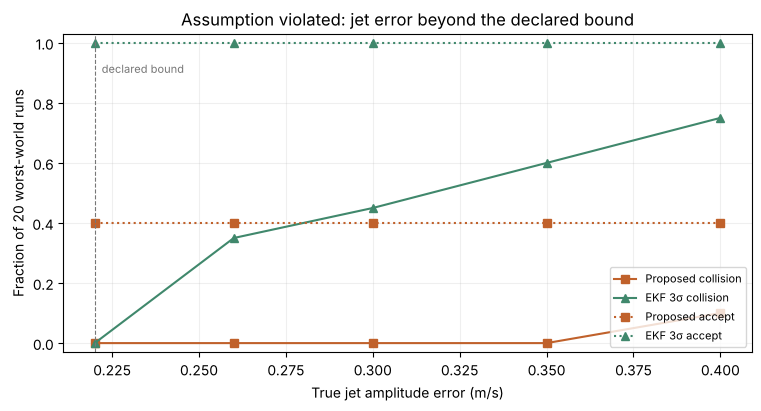

,n,filter_admit,filter_coll,filter_lost,ekf_admit,ekf_coll,ekf_lost,filter_min_clear,ekf_min_clear
level,,,,,,,,,
0.22,20,8,0,0,20,0,0,1.086226,0.058803
0.26,20,8,0,0,20,7,0,0.785820,-0.010790
0.30,20,8,0,0,20,9,0,0.485366,-0.006711
0.35,20,8,0,0,20,12,0,0.109704,-0.012450
0.40,20,8,2,0,20,15,0,-0.002773,-0.016259


In [3]:
by = av.groupby('level').agg(n=('seed', 'size'),
    filter_admit=('filter_admitted', 'sum'), filter_coll=('filter_collided', 'sum'), filter_lost=('filter_cert_lost', 'sum'),
    ekf_admit=('ekf3s_admitted', 'sum'), ekf_coll=('ekf3s_collided', 'sum'), ekf_lost=('ekf3s_cert_lost', 'sum'),
    filter_min_clear=('filter_min_clearance', 'min'), ekf_min_clear=('ekf3s_min_clearance', 'min'))
fig, ax = plt.subplots(figsize=(7.5, 4), layout='constrained')
ax.plot(by.index, by['filter_coll']/by['n'], 's-', color='#c0612b', label='Proposed collision')
ax.plot(by.index, by['ekf_coll']/by['n'], '^-', color='#40886c', label='EKF 3σ collision')
ax.plot(by.index, by['filter_admit']/by['n'], 's:', color='#c0612b', label='Proposed accept')
ax.plot(by.index, by['ekf_admit']/by['n'], '^:', color='#40886c', label='EKF 3σ accept')
ax.axvline(0.22, color='#777', ls='--', lw=.8); ax.text(0.222, .9, 'declared bound', color='#777', fontsize=8)
ax.set(xlabel='True jet amplitude error (m/s)', ylabel=f'Fraction of {int(by.n.iloc[0])} worst-world runs',
       title='Assumption violated: jet error beyond the declared bound', ylim=(-.03, 1.03))
ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.savefig(FIG/'violation_worst_world.png', dpi=200); fig.savefig(FIG/'violation_worst_world.pdf')
plt.show()
by

## 2. 随机世界，射流误差放大 2 倍

In [4]:
def violated_random(n=120):
    rng = np.random.default_rng(2027)
    out = []
    for i in range(240):
        L = float(rng.uniform(15.0, 50.0))
        s = sample_scenario(rng, 20000 + i, length=round(L, 2), width=8.0)
        out.append(replace(s, jet_amplitude_error=2*s.jet_amplitude_error))
    return out[:n]
rv = cached(RES/'violation_random.csv', violated_random(), ('filter', 'ekf3s', 'ilos07', 'oracle'))
assert 'error' not in rv or rv['error'].isna().all()
t = rates_table(rv, ['filter', 'ekf3s'], 0.0)
t.to_csv(RES/'violation_random_summary.csv', index=False)
out = (100*t.pivot_table(index='metric', columns='method', values='rate', sort=False)).round(1)
over = rv['jet_amplitude_error'].abs() > 0.22
print(f'worlds beyond the declared bound: {over.sum()}/{len(rv)}')
for m in ('filter', 'ekf3s'):
    adm = rv[m + '_admitted'].fillna(False).astype(bool)
    print(f"{m:7s} admitted {adm.sum():3d}  collided {int(rv[m+'_collided'].sum())}  "
          f"collided & beyond bound {int((rv[m+'_collided'].astype(bool) & over).sum())}  "
          f"cert lost {int(rv[m+'_cert_lost'].sum())}  min clearance (admitted) {rv.loc[adm, m+'_min_clearance'].min():.3f}")
print('ILOS 0.7 collisions:', int(rv.ilos07_collided.sum()))
out

loading violation_random.csv
worlds beyond the declared bound: 60/120
filter  admitted  19  collided 0  collided & beyond bound 0  cert lost 0  min clearance (admitted) 0.011
ekf3s   admitted  69  collided 19  collided & beyond bound 19  cert lost 0  min clearance (admitted) -0.008
ILOS 0.7 collisions: 86


method,filter,ekf3s
metric,,
accept (放行率),15.8,57.5
pass (通过率),15.8,41.7
collision (撞墙率),0.0,15.8
"false accept: admitted & collided (错误放行, 按放行数)",0.0,27.5
"false accept: admitted & infeasible (错误放行, 按放行数)",0.0,18.8
"false reject (误拒, 按能过数)",76.5,30.9
"bound coverage (误差界覆盖率, 全程)",96.7,0.0
"certification loss (认证丢失, 按放行数)",0.0,0.0
feasible (能过比例),67.5,67.5


## 结论

数字取自上面的实际运行（统一参数；横荡速度误差界 GNSS 可用时 0.025 m/s、断星时 0.015 m/s）。
**最坏世界（每个超界水平 20 次运行：5 个桥长 × 4 个世界）**

| 真实射流误差 (m/s) | 0.22（界内） | 0.26 | 0.30 | 0.35 | 0.40 |
|---|---|---|---|---|---|
| 本文方法 撞墙 / 放行 | 0/8 | 0/8 | 0/8 | 0/8 | 2/8 |
| EKF 3σ 撞墙 / 放行 | 0/20 | 7/20 | 9/20 | 12/20 | 15/20 |

- 本文方法只放行 15–18 m，那里有余量。超界 36%（0.30）时误差界几乎用满（0.97–0.99 倍）但仍覆盖；超界 59%（0.35）时误差界被突破（1.13–1.14 倍）但不撞墙；超界 82%（0.40）才在 18 m 撞墙 2 次。
- EKF 3σ 超界 18%（0.26）就开始在 21、27、33 m 撞墙，0.30 起在 18 m 也撞。
- 两者撞墙都是擦碰量级（间隙 −0.02 m 以内），因为一接近墙就判为接触、仿真停止。

**随机世界（射流误差放大 2 倍，120 个世界中 60 个超界）**
- 本文方法放行 19 次，撞墙 0；误差界覆盖率 96.7%；放行者最小间隙 0.011 m，已非常接近墙。
- EKF 3σ 放行 69 次，撞墙 19 次（错误放行率 27.5%），其中 13 次放行的是事后不可通过的桥。
- 0.7 m/s ILOS 撞墙 86/120。

**解读**：假设被违反时两种方法都不再有保证，这一点要如实写。但本文方法退化得更晚、更少，因为它在界内留下的余量（误差界只用到 0.6–0.75 倍）在超界时起了缓冲作用；
EKF 3σ 在界内已经把余量用完，一超界就撞。这是“确定性误差界”相对“3σ 裕度”的实际价值，可作为命题之外的经验证据。